# Investigating Attention Heads in In-Context Retrieval
**A small causal investigation in Qwen2.5-3B-Instruct, building on Mixing Mechanisms**

A prompt says *pen → A; ball → B* and asks where the pen is. What do individual
attention heads contribute to that lookup, and when does their contribution matter?

We begin with the [paper's](https://arxiv.org/html/2510.06182v2) residual transplant,
then look for individual head contributions. A controlled attention/value crossing
supplies misleading label evidence. We ask which later messages help the correct
answer survive, before testing the selected heads individually and together.

Every input, intervention and figure is generated here. The opening uses eight
known exploration problems; the remaining comparisons use the same 32 previously
studied, token-aligned problems. This is an exploratory reconstruction, not fresh
validation or a complete circuit.


## 1. Set up a lookup we can inspect

Each prompt lists 20 object–box declarations and asks for one object's box. Objects
and labels are randomly reassigned, so the model must use the current table. We
append the unfinished assistant prefix `Box` and read the next token, such as
`" A"` with its leading space. Probabilities use the full vocabulary. There is no
chain of thought or subsequent decoding: every call is a full prefill with no KV cache.

Transformers implements the model, NNsight reads and edits tensors, and PyTorch
runs it on CUDA. To rerun the notebook, use a fresh Python 3.12 environment with
an NVIDIA GPU. Install the following packages before starting the notebook kernel:

```bash
python -m pip install torch==2.8.0 --index-url https://download.pytorch.org/whl/cu128
python -m pip install \
    numpy==1.26.4 matplotlib==3.11.2 transformers==4.57.3 \
    nnsight==0.5.1 accelerate==1.15.0 nbformat==5.10.4 \
    nbclient==0.10.2 ipykernel==6.30.1 jupyterlab==4.4.10 \
    circuitsvis==1.43.3
jupyter lab binding-heads.ipynb
```

The experiments use Python 3.12.3, an NVIDIA A40, CUDA 12.8, CUDA-enabled Torch
`2.8.0+cu128` and BF16. The package versions are also listed in
[requirements.txt](requirements.txt). After installing packages, restart the
kernel and choose **Restart Kernel and Run All Cells** in JupyterLab. Saved
outputs can be read without a kernel or GPU. `RUN_ALL_FAMILIES=False` runs one
family per section as a technical smoke test, not a scientific result.


In [1]:
from pathlib import Path
from datetime import datetime, timezone
from functools import partial
import hashlib
import html
import importlib.metadata
import json
import math
import random
import uuid

import numpy as np
import matplotlib.pyplot as plt
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer
from nnsight import NNsight
from IPython.display import HTML, Markdown, display

RUN_MODEL = True
RUN_ALL_FAMILIES = True
DEVICE = 'cuda'
MODEL_ID = "Qwen/Qwen2.5-3B-Instruct"
MODEL_REVISION = "aa8e72537993ba99e69dfaafa59ed015b17504d1"
N_BLOCKS, N_HEADS, N_KV_HEADS, D_HEAD, D_MODEL = 36, 16, 2, 128, 2048
RESIDUAL_SEED, SCREEN_SEED, CONTENT_SEED = 31001, 300011, 27001

PROJECT_DIR = Path.cwd()
if PROJECT_DIR.name == "notebooks" and (PROJECT_DIR.parent / "README.md").exists():
    PROJECT_DIR = PROJECT_DIR.parent
MODEL_CACHE = PROJECT_DIR / ".cache/huggingface-015"

assert RUN_MODEL and DEVICE == "cuda" and torch.cuda.is_available(), "CUDA GPU required"
assert torch.__version__.split("+")[0] == "2.8.0"
for package, version in {
    "transformers": "4.57.3",
    "nnsight": "0.5.1",
    "circuitsvis": "1.43.3",
}.items():
    assert importlib.metadata.version(package) == version

torch.set_num_threads(4)
tokenizer = AutoTokenizer.from_pretrained(
    MODEL_ID, revision=MODEL_REVISION, cache_dir=MODEL_CACHE, trust_remote_code=False
)
plt.rcParams.update(
    {
        "figure.dpi": 115,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "font.size": 10,
    }
)
BLUE, ORANGE, GREY = "#3478a8", "#d47935", "#8b9299"
print("GPU:", torch.cuda.get_device_name(), "| Torch:", torch.__version__)


GPU: NVIDIA A40 | Torch: 2.8.0+cu128


In [2]:
def show_table(rows):
    """Render small tables without adding a dataframe dependency."""
    rows = list(rows)
    columns = list(rows[0])
    header = "".join(f"<th>{html.escape(str(column))}</th>" for column in columns)
    body = "".join(
        "<tr>"
        + "".join(f"<td>{html.escape(str(row[column]))}</td>" for column in columns)
        + "</tr>"
        for row in rows
    )
    display(
        HTML(f"<table><thead><tr>{header}</tr></thead><tbody>{body}</tbody></table>")
    )


def probability_of_role(observation, role):
    label = observation["roles"][role]
    label_logits = dict(
        zip(observation["candidate_letters"], observation["candidate_logits"])
    )
    return math.exp(label_logits[label] - observation["logsumexp"])


def logit_margin(observation, positive_role, negative_role):
    label_logits = dict(
        zip(observation["candidate_letters"], observation["candidate_logits"])
    )
    return (
        label_logits[observation["roles"][positive_role]]
        - label_logits[observation["roles"][negative_role]]
    )


def predicts_role(observation, role):
    label = observation["roles"][role]
    token_id = observation["candidate_ids"][
        observation["candidate_letters"].index(label)
    ]
    return observation["top_tied_ids"] == [token_id]


def top_label(observation):
    labels = dict(zip(observation["candidate_ids"], observation["candidate_letters"]))
    return labels.get(
        observation["top1_id"], f"vocabulary token {observation['top1_id']}"
    )


def bootstrap_mean(values, seed, resamples=5000):
    """Resample underlying problems, keeping one paired effect per problem."""
    values = np.asarray(values, dtype=np.float64)
    assert values.ndim == 1 and len(values) and np.isfinite(values).all()
    indices = np.random.default_rng(seed).integers(
        len(values), size=(resamples, len(values))
    )
    means = values[indices].mean(axis=1)
    return {
        "mean": float(values.mean()),
        "ci95": np.quantile(means, [0.025, 0.975]).tolist(),
        "n_families": len(values),
    }


def format_interval(summary):
    lower, upper = summary["ci95"]
    return f"{summary['mean']:.5f} [{lower:.5f}, {upper:.5f}]"


def confidence_arrays(summaries):
    means = np.array([summary["mean"] for summary in summaries])
    bounds = np.array([summary["ci95"] for summary in summaries])
    return means, np.stack((means - bounds[:, 0], bounds[:, 1] - means))


def plot_bars(axis, positions, summaries, **style):
    means, errors = confidence_arrays(summaries)
    return axis.bar(positions, means, yerr=errors, capsize=3, **style)


# Named readouts shared by the main-cohort analyses; their roles are defined below.
probability_L = partial(probability_of_role, role="L")
probability_C = partial(probability_of_role, role="C")
margin_C_minus_L = partial(logit_margin, positive_role="C", negative_role="L")


For each problem, build three prompts. **R** is the original table and question.
**D** permutes its assignments and asks about a different object. **O** uses R's
table but explicitly asks D's question. Thus R's answer is **U**, D's answer is
**D**, and O's answer is **L**. The same letter can name a prompt or its answer
role; the printed example below gives the actual labels.

One seeded generator supplies these triples. The opening uses eight known
exploration families. Later we use a separate set of 32 known families, restricted
to single-token objects so declaration positions align for attention/value crossing.
Fixed seeds make the prompt triples reproducible.


In [3]:
OBJECTS = """
egg fan tea engine plate gift wire watch cross boat game rose shell seed magnet suit
ticket glass tie card brain fig wheel machine note drink bread camera bill chemical
clock flower creature rock plant sheet leaf block newspaper disk boot medicine
coffee book ball string fish crown branch phone plane apple cup bell brick document
file bus bag drug pot computer mirror stone radio dress meat train bomb letter
guitar hat map magazine coat television painting picture milk pipe ice key
""".split()
LETTERS = list("ABCDEFGHIJKLMNOPQRSTUVWXYZ")


def render_prompt(bindings, query, tokenizer):
    """Render chat text and locate each leading-space label token."""
    raw_text = ""
    label_char_spans = []
    for row_index, (object_name, label) in enumerate(bindings):
        if row_index > 0:
            raw_text += ", and " if row_index == len(bindings) - 1 else ", "
        clause = f"the {object_name} is in Box {label}"
        if row_index == 0:
            clause = clause[0].upper() + clause[1:]
        # A label is one ASCII letter; include its preceding space in the span.
        label_start = len(raw_text) + len(clause) - 2
        label_char_spans.append((label_start, label_start + 2))
        raw_text += clause
    raw_text += (
        ". Respond in one word, only the answer and nothing else: "
        f"Which box is the {query} in? Box Answer:"
    )
    rendered_text = tokenizer.apply_chat_template(
        [{"role": "user", "content": raw_text}],
        tokenize=False,
        add_generation_prompt=True,
    )
    encoded = tokenizer(
        rendered_text, add_special_tokens=False, return_offsets_mapping=True
    )
    token_ids, offsets = encoded["input_ids"], encoded["offset_mapping"]
    message_offset = rendered_text.index(raw_text)
    clause_spans = []
    for start, end in label_char_spans:
        positions = [
            position
            for position, (token_start, token_end) in enumerate(offsets)
            if token_end > token_start
            and token_start < end + message_offset
            and token_end > start + message_offset
        ]
        assert len(positions) == 1
        clause_spans.append(
            {"box_token_position": positions[0], "box_token_positions": positions}
        )
    label_encodings = [
        tokenizer.encode(" " + label, add_special_tokens=False) for _, label in bindings
    ]
    assert all(len(encoding) == 1 for encoding in label_encodings)
    candidate_ids = [encoding[0] for encoding in label_encodings]
    after_box = tokenizer.encode(rendered_text + "Box", add_special_tokens=False)
    assert after_box[: len(token_ids)] == token_ids
    for (_, label), token_id, span in zip(bindings, candidate_ids, clause_spans):
        assert token_ids[span["box_token_position"]] == token_id
        assert tokenizer.encode(
            rendered_text + "Box " + label, add_special_tokens=False
        ) == after_box + [token_id]
    query_row = next(
        row for row, (object_name, _) in enumerate(bindings) if object_name == query
    )
    return {
        "bindings": bindings,
        "query_object": query,
        "query_row1based": query_row + 1,
        "raw_text": raw_text,
        "rendered_text": rendered_text,
        "input_ids": token_ids,
        "continuation_prefixes": {"Box": {"input_ids": after_box}},
        "candidate_letters": [label for _, label in bindings],
        "candidate_ids": candidate_ids,
        "answer_letter": bindings[query_row][1],
        "clause_spans": clause_spans,
    }


def input_ids(prompt):
    return prompt["continuation_prefixes"]["Box"]["input_ids"]


def generate_problem(namespace, index, *, one_token_objects=False):
    objects = [
        word
        for word in OBJECTS
        if not one_token_objects
        or len(tokenizer.encode(" " + word, add_special_tokens=False)) == 1
    ]
    seed = int(hashlib.sha256(f"{namespace}|{index}".encode()).hexdigest(), 16)
    rng = random.Random(seed)
    # Keep these draws in order: they define the already-studied problem set.
    recipient_bindings = list(
        map(list, zip(rng.sample(objects, 20), rng.sample(LETTERS, 20)))
    )
    query_object = recipient_bindings[3][0]
    donor_objects = rng.sample(
        [name for name, _ in recipient_bindings if name != query_object], 19
    )
    donor_answer = recipient_bindings[9][1]
    donor_labels = rng.sample(
        [label for _, label in recipient_bindings if label != donor_answer], 19
    )
    donor_bindings = list(map(list, zip(donor_objects, donor_labels)))
    donor_bindings.insert(5, [query_object, donor_answer])
    return {
        "family_id": f"{namespace}:{index:04d}",
        "R": render_prompt(recipient_bindings, recipient_bindings[19][0], tokenizer),
        "D": render_prompt(donor_bindings, query_object, tokenizer),
        "O": render_prompt(recipient_bindings, query_object, tokenizer),
    }


In [4]:
all_opening_problems = [generate_problem("017-explore-v1", index) for index in range(8)]
all_main_problems = [
    generate_problem(
        "027-parallel-lookup-confirmation-v1", index, one_token_objects=True
    )
    for index in range(32)
]
opening_problems = (
    all_opening_problems if RUN_ALL_FAMILIES else all_opening_problems[:1]
)
main_problems = all_main_problems if RUN_ALL_FAMILIES else all_main_problems[:1]
example_problem = main_problems[0]
example_ordinary = example_problem["O"]


# Split by binding table, not by repeated interventions on that table.
def binding_tables(problems):
    return {
        tuple(sorted(map(tuple, problem[key]["bindings"])))
        for problem in problems
        for key in ("R", "D")
    }


assert binding_tables(all_opening_problems).isdisjoint(
    binding_tables(all_main_problems)
)
print(example_ordinary["raw_text"])
example_token_ids = input_ids(example_ordinary)
show_table(
    [
        {
            "position": index,
            "token ID": example_token_ids[index],
            "text": repr(tokenizer.decode([example_token_ids[index]])),
        }
        for index in range(len(example_token_ids) - 8, len(example_token_ids))
    ]
)


The stone is in Box V, the machine is in Box E, the magnet is in Box P, the brick is in Box Y, the disk is in Box J, the television is in Box Q, the egg is in Box H, the creature is in Box N, the block is in Box S, the book is in Box I, the document is in Box Z, the brain is in Box R, the suit is in Box U, the plate is in Box A, the gift is in Box O, the key is in Box B, the radio is in Box L, the dress is in Box T, the pot is in Box X, and the train is in Box M. Respond in one word, only the answer and nothing else: Which box is the brick in? Box Answer:


position,token ID,text
185,21806,' Answer'
186,25,':'
187,151645,'<|im_end|>'
188,198,'\n'
189,151644,'<|im_start|>'
190,77091,'assistant'
191,198,'\n'
192,1611,'Box'


Qwen has 36 blocks, 16 query heads, two shared KV heads and 128 coordinates per
query head. All indices are zero-based: **31.7 means block 31, head 7**.

The patch constructors name the two sites explicitly:

- `residual_patch`: the final token's residual entering a block, `[1, 2048]`.
- `head_output_patch`: one final-token weighted value sum before `o_proj`, `[1, 128]`.
  This is TransformerLens's `hook_z` site.

Each captured block has `residual_before` / `residual_used` and
`head_output_before` / `head_output_used`: before the edit versus actually consumed.
`attention` uses `[batch, head, destination, source]`, as in TransformerLens;
`values` uses `[batch, sequence, KV head, head width]`.

The tracing helper below keeps the actual tensor edits explicit. Ordinary hooks
independently observe consumed tensors; verification includes untouched positions,
other heads, hook cleanup and the preceding token's logits. A separate Transformers
pre-hook implementation checks the same selected edits.


In [5]:
def residual_patch(block, value):
    """Replace the final token's block-input residual, shaped [1, D_MODEL]."""
    return {"layer": block, "kind": "r", "value": value}


def head_output_patch(block, head, value):
    """Replace one final-token head output before o_proj, shaped [1, D_HEAD]."""
    return {"layer": block, "kind": "z", "head": head, "value": value}


def tensor_sha(tensor):
    array = tensor.detach().contiguous().cpu()
    header = json.dumps(
        {"shape": list(array.shape), "dtype": str(array.dtype)},
        sort_keys=True,
    ).encode()
    return hashlib.sha256(
        header + array.view(torch.uint8).numpy().tobytes()
    ).hexdigest()


def _verify_block_patches(activations, patches, position):
    """Check the consumed tensors, including every unpatched token and head."""
    expected_residual = activations["residual_before"].clone()
    expected_head_output = activations["head_output_before"].clone()
    receipts = []

    for patch in patches:
        if patch["kind"] == "r":
            expected_residual[:, position] = patch["value"].to(expected_residual)
            actual = activations["residual_used"][:, position]
        else:
            assert patch["kind"] == "z"
            expected_head_output[:, position, patch["head"]] = patch["value"].to(
                expected_head_output
            )
            actual = activations["head_output_used"][:, position, patch["head"]]

        assert torch.equal(actual, patch["value"].to(actual))
        receipts.append(
            {
                **{key: value for key, value in patch.items() if key != "value"},
                "requested_sha256": tensor_sha(patch["value"]),
                "actual_sha256": tensor_sha(actual),
                "exact": True,
            }
        )

    assert torch.equal(activations["residual_used"], expected_residual)
    assert torch.equal(activations["head_output_used"], expected_head_output)
    return receipts


In [6]:
def run_forward(model, traced_model, token_ids, patches=(), capture_blocks=()):
    """Run one prefill with final-token patches and no KV cache.

    Warm up traced_model once before calling, so hook cleanup can be checked.
    Residuals are [1, sequence, D_MODEL], values [1, sequence, N_KV_HEADS,
    D_HEAD], head outputs [1, sequence, N_HEADS, D_HEAD], and attention
    [1, N_HEADS, destination, source]. Ordinary hooks observe the residual
    consumed by each block and the head outputs consumed by o_proj.
    """
    tokens = torch.tensor([token_ids], device=DEVICE)
    position = len(token_ids) - 1
    capture_blocks = sorted(set(capture_blocks) | {patch["layer"] for patch in patches})
    patch_sites = {
        (patch["layer"], patch["kind"], patch.get("head")) for patch in patches
    }
    assert len(patch_sites) == len(patches)

    activations = {}
    residuals_used = {}
    head_outputs_used = {}
    attention = {}
    handles = []

    def hook_ids():
        return [
            (tuple(module._forward_hooks), tuple(module._forward_pre_hooks))
            for module in model.modules()
        ]

    hooks_before = hook_ids()
    for block_index in capture_blocks:
        block = model.model.layers[block_index]

        def read_residual(module, args, block_index=block_index):
            residuals_used[block_index] = args[0].detach().clone()

        def read_head_output(module, args, output, block_index=block_index):
            head_outputs_used[block_index] = (
                args[0].detach().clone().reshape(1, len(token_ids), N_HEADS, D_HEAD)
            )

        def read_attention(module, args, output, block_index=block_index):
            attention[block_index] = output[1].detach().clone()

        handles += [
            block.register_forward_pre_hook(read_residual),
            block.self_attn.o_proj.register_forward_hook(read_head_output),
            block.self_attn.register_forward_hook(read_attention),
        ]

    try:
        with torch.inference_mode(), traced_model.trace(
            tokens, use_cache=False, logits_to_keep=0
        ):
            for block_index in capture_blocks:
                block = traced_model.model.layers[block_index]
                activations[block_index] = {
                    "residual_before": block.input.clone().save()
                }
                residual_patches = [
                    patch
                    for patch in patches
                    if patch["layer"] == block_index and patch["kind"] == "r"
                ]
                if residual_patches:
                    changed = block.input.clone()
                    changed[:, position] = residual_patches[0]["value"].to(changed)
                    block.input = changed

                activations[block_index]["values"] = (
                    block.self_attn.v_proj.output.reshape(
                        1, len(token_ids), N_KV_HEADS, D_HEAD
                    )
                    .clone()
                    .save()
                )
                raw_head_output = block.self_attn.o_proj.input
                head_output = raw_head_output.reshape(
                    1, len(token_ids), N_HEADS, D_HEAD
                )
                activations[block_index][
                    "head_output_before"
                ] = head_output.clone().save()
                head_patches = [
                    patch
                    for patch in patches
                    if patch["layer"] == block_index and patch["kind"] == "z"
                ]
                if head_patches:
                    changed = head_output.clone()
                    for patch in head_patches:
                        changed[:, position, patch["head"]] = patch["value"].to(changed)
                    block.self_attn.o_proj.input = changed.reshape_as(raw_head_output)

            logits = (
                traced_model.output.logits[:, [position - 1, position], :]
                .float()
                .save()
            )
    finally:
        for handle in reversed(handles):
            handle.remove()

    assert hook_ids() == hooks_before
    receipts = []
    for block_index in capture_blocks:
        block_activations = activations[block_index]
        block_activations.update(
            residual_used=residuals_used[block_index],
            head_output_used=head_outputs_used[block_index],
            attention=attention[block_index],
        )
        block_patches = [patch for patch in patches if patch["layer"] == block_index]
        receipts.extend(
            _verify_block_patches(block_activations, block_patches, position)
        )

    assert len(receipts) == len(patches)
    return {"activations": activations, "logits": logits, "edits": receipts}


In [7]:
def reference_forward(model, token_ids, patches=()):
    """Independent HF prefill using pre-hooks at block input or o_proj input."""
    handles = []
    try:
        for patch in patches:
            block = model.model.layers[patch["layer"]]
            module = block if patch["kind"] == "r" else block.self_attn.o_proj

            def replace(module, args, patch=patch):
                raw = args[0]
                changed = (
                    raw.clone()
                    if patch["kind"] == "r"
                    else raw.clone().reshape(1, len(token_ids), N_HEADS, D_HEAD)
                )
                if patch["kind"] == "r":
                    changed[:, -1] = patch["value"].to(changed)
                else:
                    changed[:, -1, patch["head"]] = patch["value"].to(changed)
                return (changed.reshape_as(raw),) + args[1:]

            handles.append(module.register_forward_pre_hook(replace))

        with torch.inference_mode():
            return (
                model(
                    torch.tensor([token_ids], device=DEVICE),
                    use_cache=False,
                    logits_to_keep=0,
                )
                .logits[:, [-2, -1]]
                .float()
            )
    finally:
        for handle in reversed(handles):
            handle.remove()


In [8]:
model = (
    AutoModelForCausalLM.from_pretrained(
        MODEL_ID,
        revision=MODEL_REVISION,
        dtype=torch.bfloat16,
        device_map=DEVICE,
        attn_implementation="eager",
        cache_dir=MODEL_CACHE,
        trust_remote_code=False,
    )
    .eval()
    .requires_grad_(False)
)
architecture = (
    model.config.num_hidden_layers,
    model.config.hidden_size,
    model.config.num_attention_heads,
    model.config.num_key_value_heads,
)
assert architecture == (N_BLOCKS, D_MODEL, N_HEADS, N_KV_HEADS)
assert all(parameter.device.type == "cuda" for parameter in model.parameters())
traced_model = NNsight(model)

# Initialize NNsight's own hooks before verifying that our hooks are removed.
with torch.inference_mode(), traced_model.trace(
    torch.tensor([input_ids(example_ordinary)], device=DEVICE),
    use_cache=False,
    logits_to_keep=0,
):
    warmup_logits = traced_model.output.logits[:, -1].save()


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

### Record observations separately from experiment logic

The following helpers handle run metadata and first-problem tensor witnesses.
They do not choose interventions. `run_case` makes one live model call and records
its result; `observation` reads that in-memory record. The `family_id` field identifies the underlying problem.


In [9]:
timestamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
RUN_DIR = PROJECT_DIR / "runs" / f"notebook-binding-{timestamp}-{uuid.uuid4().hex[:8]}"
RUN_DIR.mkdir(parents=True, exist_ok=False)
observations, tensor_witnesses, checks = {}, {}, {}
first_problem_ids = {
    "opening": opening_problems[0]["family_id"],
    "main": example_problem["family_id"],
}

run_config = {
    "model": MODEL_ID,
    "revision": MODEL_REVISION,
    "device": DEVICE,
    "dtype": "bfloat16",
    "attention": "eager",
    "batch_size": 1,
    "use_cache": False,
    "all_frozen_families": RUN_ALL_FAMILIES,
    "new_validation": False,
    "gpu": torch.cuda.get_device_name(),
    "cuda_runtime": torch.version.cuda,
    "versions": {
        package: importlib.metadata.version(package)
        for package in ("torch", "transformers", "nnsight", "circuitsvis")
    },
}
input_payload = {
    "main": all_main_problems,
    "exploration": all_opening_problems,
    "opening_variant": "00 only",
}
(RUN_DIR / "generated_inputs.json").write_text(json.dumps(input_payload))
(RUN_DIR / "config.json").write_text(json.dumps(run_config, indent=2))


def answer_roles(problem, study):
    if study == "opening":
        return {
            "U": problem["R"]["answer_letter"],
            "L": problem["O"]["answer_letter"],
            "D": problem["D"]["answer_letter"],
        }
    ordinary, donor = problem["O"], problem["D"]
    return {
        "L": ordinary["answer_letter"],
        "C": donor["bindings"][ordinary["query_row1based"] - 1][1],
        "D": donor["answer_letter"],
    }


print("Fresh evidence directory:", RUN_DIR)


Fresh evidence directory: /workspace/reasoning-interp/runs/notebook-binding-20261113T000932Z-f8303614


In [10]:
def _capture_witness(result, patches, condition):
    snapshots = {}
    for block, cache in result["activations"].items():
        snapshot = {
            "attention": cache["attention"][:, :, -1].cpu(),
            "values": cache["values"].cpu(),
            "residual_before": cache["residual_before"][:, -1].cpu(),
            "residual_used": cache["residual_used"][:, -1].cpu(),
            "head_output_before": cache["head_output_before"][:, -1].cpu(),
            "head_output_used": cache["head_output_used"][:, -1].cpu(),
            "full_hashes": {name: tensor_sha(tensor) for name, tensor in cache.items()},
        }
        if condition.startswith("native."):
            snapshot["full_attention"] = cache["attention"].cpu()
        if condition in ("native.O", "hybrid.H", "screen.H", "AV.31.OD"):
            snapshot["full_head_output_before"] = cache["head_output_before"].cpu()
        if condition in (
            "native.R",
            "native.D",
            "residual.layer31",
            "hybrid.H",
            "screen.H",
        ):
            snapshot["full_residual_before"] = cache["residual_before"].cpu()
        snapshots[block] = snapshot
    return {
        "logits": result["logits"].cpu(),
        "patches": [{**patch, "value": patch["value"].cpu()} for patch in patches],
        "activations": snapshots,
    }


def _verify_and_snapshot(problem, prompt_key, condition, patches, result, study):
    blocks = (31,) if study == "opening" else (31, 32)
    captured = {
        block: result["activations"][block]
        for block in blocks
        if block in result["activations"]
    }
    key = (study, problem["family_id"], condition)
    tensor_witnesses[key] = _capture_witness(
        {**result, "activations": captured}, patches, condition
    )
    reference = reference_forward(model, input_ids(problem[prompt_key]), patches)
    assert torch.equal(reference, result["logits"])
    checks[f"reference:{study}:{condition}"] = True


In [11]:
def _record_observation(problem, prompt_key, condition, result, study, metadata):
    prompt = problem[prompt_key]
    logits = result["logits"][0, -1]
    row = {
        "experiment": study,
        "family_id": problem["family_id"],
        "condition": condition,
        "prompt_key": prompt_key,
        "roles": answer_roles(problem, study),
        "candidate_ids": prompt["candidate_ids"],
        "candidate_letters": prompt["candidate_letters"],
        "candidate_logits": logits[prompt["candidate_ids"]].tolist(),
        "extra_logits": {},
        "logsumexp": float(logits.logsumexp(0)),
        "top1_id": int(logits.argmax()),
        "top_tied_ids": (logits == logits.max()).nonzero().flatten().tolist(),
        "input_ids": input_ids(prompt),
        "actual_edits": result["edits"],
        "error": None,
        "finish_reason": "not_applicable_single_prefill",
        **metadata,
    }
    key = (study, problem["family_id"], condition)
    assert key not in observations, f"Repeated condition: {key}"
    observations[key] = row
    with (RUN_DIR / "records.jsonl").open("a") as file:
        file.write(json.dumps(row) + "\n")
    return row


In [12]:
def run_case(
    problem,
    prompt_key,
    condition,
    patches=(),
    *,
    study="main",
    capture_blocks=(31, 32),
    **metadata
):
    """Run one prefill and record it; interventions are explicit at each call site."""
    result = run_forward(
        model, traced_model, input_ids(problem[prompt_key]), patches, capture_blocks
    )
    result["observation"] = _record_observation(
        problem, prompt_key, condition, result, study, metadata
    )
    if problem["family_id"] == first_problem_ids[study]:
        _verify_and_snapshot(problem, prompt_key, condition, patches, result, study)
    return result


In [13]:
def observation(problem, condition, study="main"):
    return observations[study, problem["family_id"], condition]


def has_case(problem, condition, study="main"):
    return (study, problem["family_id"], condition) in observations


def condition_values(problems, condition, metric):
    return np.array([metric(observation(problem, condition)) for problem in problems])


def paired_summary(problems, treatment, baseline, metric):
    differences = condition_values(problems, treatment, metric) - condition_values(
        problems, baseline, metric
    )
    return bootstrap_mean(differences, CONTENT_SEED)


## 2. Find a candidate with two simple interventions

First reproduce the paper's motivating observation. Run D and copy its residual
at the final `Box` into the same position of R, immediately before a chosen block.
Call the resulting run **H**. H still contains R's text; only that one residual
vector is transplanted. Does it favor U (R's original answer), D (the donor's
answer), or L (D's question answered using R's table)?

Sweep every block boundary and plot all three probabilities. We use the following
exploratory rule: choose the latest block with mean p(L) ≥ .25 and mean p(L) − p(D)
≥ .10. This chooses a place to inspect, not a complete retrieval circuit.

Use one pair from each of eight exploration families. Each family contributes
one value to the mean and its bootstrap interval. These are previously studied
pairs, separate from the main cohort; these comparisons provide no fresh validation.


In [14]:
opening_example = opening_problems[0]
show_table(
    [
        {
            "prompt": key,
            "question": opening_example[key]["query_object"],
            "answer": opening_example[key]["answer_letter"],
        }
        for key in ("R", "D", "O")
    ]
)
example_rows = sorted(
    {opening_example[key]["query_row1based"] - 1 for key in ("R", "D", "O")}
)
show_table(
    [
        {
            "row": row + 1,
            "R declaration": " → ".join(opening_example["R"]["bindings"][row]),
            "D declaration": " → ".join(opening_example["D"]["bindings"][row]),
        }
        for row in example_rows
    ]
)


prompt,question,answer
R,cross,O
D,machine,L
O,machine,Y


row,R declaration,D declaration
4,machine → Y,camera → J
6,dress → K,machine → L
20,cross → O,game → N


In [15]:
all_blocks = list(range(N_BLOCKS))
residual_observations = []
donor_residuals = {}

for problem in opening_problems:
    assert len(input_ids(problem["R"])) == len(input_ids(problem["D"]))
    assert len(set(answer_roles(problem, "opening").values())) == 3
    recipient_run = run_case(
        problem, "R", "native.R", study="opening", capture_blocks=all_blocks
    )
    donor_run = run_case(
        problem, "D", "native.D", study="opening", capture_blocks=all_blocks
    )
    donor_residuals[problem["family_id"]] = {
        block: cache["residual_before"][:, -1].clone()
        for block, cache in donor_run["activations"].items()
    }

    for block in all_blocks:
        donor_vector = donor_residuals[problem["family_id"]][block]
        patch = residual_patch(block, donor_vector)
        hybrid_run = run_case(
            problem,
            "R",
            f"residual.layer{block:02d}",
            [patch],
            study="opening",
            capture_blocks=(block,),
            layer=block,
        )
        assert torch.equal(hybrid_run["logits"][:, 0], recipient_run["logits"][:, 0])
        residual_observations.append(hybrid_run["observation"])

        if problem == opening_problems[0] and block == 31:
            own_vector = recipient_run["activations"][block]["residual_before"][:, -1]
            identity = run_forward(
                model,
                traced_model,
                input_ids(problem["R"]),
                [residual_patch(block, own_vector)],
                (block,),
            )
            assert torch.equal(identity["logits"], recipient_run["logits"])
            assert torch.equal(
                reference_forward(model, input_ids(problem["R"])),
                recipient_run["logits"],
            )
            checks["residual_identity"] = True
    del recipient_run, donor_run, hybrid_run

residual_summary = []
for block in all_blocks:
    block_rows = [row for row in residual_observations if row["layer"] == block]
    role_summaries = {
        role: bootstrap_mean(
            [probability_of_role(row, role) for row in block_rows], RESIDUAL_SEED
        )
        for role in ("U", "L", "D")
    }
    residual_summary.append({"layer": block, "stats": role_summaries})

eligible_blocks = [
    entry["layer"]
    for entry in residual_summary
    if entry["stats"]["L"]["mean"] >= 0.25
    and entry["stats"]["L"]["mean"] - entry["stats"]["D"]["mean"] >= 0.10
]
retrieval_block = max(eligible_blocks) if RUN_ALL_FAMILIES else 31
assert retrieval_block == 31, "Inspect a changed boundary; do not retune the rule."
next_block = retrieval_block + 1


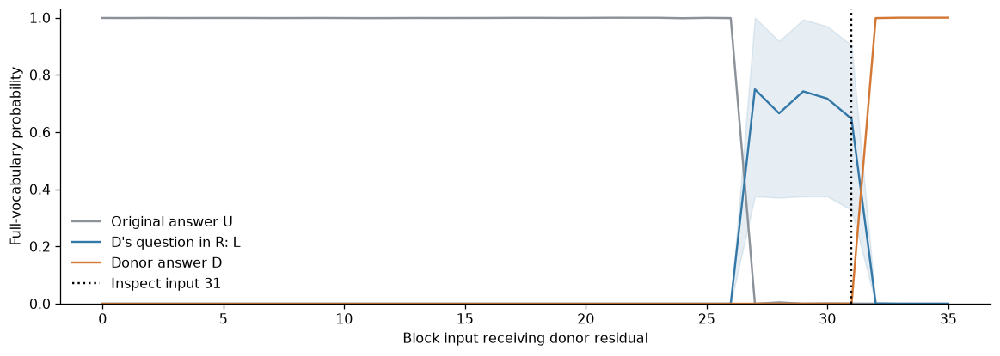

**Observation.** At input 31, mean p(L) is 0.646. The transplant can favor D's question answered using R's table. Which head messages help sustain L here?

In [16]:
fig, axis = plt.subplots(figsize=(10, 3.5), layout="constrained")
for role, label, color in [
    ("U", "Original answer U", GREY),
    ("L", "D's question in R: L", BLUE),
    ("D", "Donor answer D", ORANGE),
]:
    summaries = [entry["stats"][role] for entry in residual_summary]
    means, _ = confidence_arrays(summaries)
    lower = [summary["ci95"][0] for summary in summaries]
    upper = [summary["ci95"][1] for summary in summaries]
    axis.plot(all_blocks, means, color=color, label=label)
    axis.fill_between(all_blocks, lower, upper, color=color, alpha=0.12)
axis.axvline(
    retrieval_block,
    linestyle=":",
    color="black",
    label=f"Inspect input {retrieval_block}",
)
axis.set(
    xlabel="Block input receiving donor residual",
    ylabel="Full-vocabulary probability",
    ylim=(0, 1.03),
)
axis.legend(frameon=False)
plt.show()
display(
    Markdown(
        (
            f"**Observation.** At input {retrieval_block}, mean p(L) is "
            f"{residual_summary[retrieval_block]['stats']['L']['mean']:.3f}. The "
            "transplant can favor D's question answered using R's table. Which "
            "head messages help sustain L here?"
        )
    )
)


### Which head messages contribute in this context?

Keep the residual transplant into block 31 fixed. Set one head's final-position
Z slice to zero and measure the loss of p(L), relative to intact H. Repeat for all
16 heads. We also apply the same deletions to **ordinary O**, which explicitly asks
the same question using R's table. Both contexts therefore target the same label L.

Rank heads by their mean p(L) loss in H. Also inspect L−U logit-margin loss, since
near-ceiling probabilities can hide effects. Individual-family dots keep uneven
effects visible. Removing a final message can show a conditional contribution;
surviving answers do not prove an unchanged mechanism, and earlier positions remain intact.


In [17]:
def screen_heads(
    problem,
    prompt_key,
    block,
    context,
    baseline,
    background=(),
    *,
    study="main",
    rival="C",
):
    """Delete one final message at a time, keeping the background fixed."""
    effects = []
    before = baseline["observation"]
    for head in range(N_HEADS):
        if study == "opening":
            prefix = "conditional" if context == "H" else "query_matched"
        else:
            prefix = f"screen.{context}"
        zero = torch.zeros_like(
            baseline["activations"][block]["head_output_before"][:, -1, head]
        )
        patches = list(background) + [head_output_patch(block, head, zero)]
        deleted = run_case(
            problem,
            prompt_key,
            f"{prefix}.head{head}.zero",
            patches,
            study=study,
            capture_blocks=tuple(baseline["activations"]),
            context=context,
            head=head,
        )
        assert torch.equal(deleted["logits"][:, 0], baseline["logits"][:, 0])
        for captured_block, original in baseline["activations"].items():
            if captured_block > block:
                continue
            current = deleted["activations"][captured_block]
            upstream_fields = (
                "residual_before",
                "residual_used",
                "values",
                "attention",
                "head_output_before",
            )
            assert all(
                torch.equal(current[name], original[name]) for name in upstream_fields
            )
            expected = original["head_output_used"].clone()
            if captured_block == block:
                expected[:, -1, head] = 0
            assert torch.equal(current["head_output_used"], expected)
        checks[f"ablation:{study}:{problem['family_id']}:{context}:{head}"] = True
        after = deleted["observation"]
        effects.append(
            {
                "family_id": problem["family_id"],
                "context": context,
                "head": head,
                "loss_pL": probability_of_role(before, "L")
                - probability_of_role(after, "L"),
                "loss_margin": logit_margin(before, "L", rival)
                - logit_margin(after, "L", rival),
                "before_correct": predicts_role(before, "L"),
                "after_correct": predicts_role(after, "L"),
            }
        )
        del deleted
    return effects


In [18]:
def screen_values(effects, context, head, metric="loss_pL"):
    return np.array(
        [
            effect[metric]
            for effect in effects
            if effect["context"] == context and effect["head"] == head
        ]
    )


def summarize_screen(effects, context):
    return {
        head: {
            metric: bootstrap_mean(
                screen_values(effects, context, head, metric), SCREEN_SEED, 10000
            )
            for metric in ("loss_pL", "loss_margin")
        }
        for head in range(N_HEADS)
    }


def rank_heads(summary):
    return sorted(summary, key=lambda head: (-summary[head]["loss_pL"]["mean"], head))


def plot_head_screen(effects, summaries, block, contexts, *, margin_label=None):
    metrics = [("loss_pL", "Loss of p(L)")]
    if margin_label:
        metrics.append(("loss_margin", margin_label))
    fig, axes = plt.subplots(
        len(metrics), 1, figsize=(10, 3.2 * len(metrics)), layout="constrained"
    )
    colors = {"H": "#669d66", "O": ORANGE, "X": BLUE}
    for axis, (metric, label) in zip(np.atleast_1d(axes), metrics):
        for context_index, context in enumerate(contexts):
            offset = (context_index - (len(contexts) - 1) / 2) * 0.22
            estimates = [summaries[context][head][metric] for head in range(N_HEADS)]
            means, errors = confidence_arrays(estimates)
            axis.errorbar(
                np.arange(N_HEADS) + offset,
                means,
                yerr=errors,
                fmt="o",
                capsize=2,
                markersize=4,
                color=colors[context],
                label=context,
            )
            for head in range(N_HEADS):
                points = screen_values(effects, context, head, metric)
                axis.scatter(
                    head + offset + np.linspace(-0.06, 0.06, len(points)),
                    points,
                    s=7,
                    color=colors[context],
                    alpha=0.15,
                )
        axis.axhline(0, color=GREY, linewidth=0.6)
        axis.set_xticks(
            range(N_HEADS), [f"{block}.{head}" for head in range(N_HEADS)], rotation=45
        )
        axis.set(xlabel="Deleted final-position head", ylabel=label)
        axis.legend(frameon=False)
    plt.show()


In [19]:
opening_ablation_effects = []
for problem in opening_problems:
    donor_vector = donor_residuals[problem["family_id"]][retrieval_block]
    background = [residual_patch(retrieval_block, donor_vector)]
    hybrid = run_case(
        problem,
        "R",
        "hybrid.H",
        background,
        study="opening",
        capture_blocks=(retrieval_block,),
    )
    ordinary = run_case(
        problem, "O", "native.O", study="opening", capture_blocks=(retrieval_block,)
    )
    opening_ablation_effects.extend(
        screen_heads(
            problem,
            "R",
            retrieval_block,
            "H",
            hybrid,
            background,
            study="opening",
            rival="U",
        )
    )
    opening_ablation_effects.extend(
        screen_heads(
            problem, "O", retrieval_block, "O", ordinary, study="opening", rival="U"
        )
    )

    if problem == opening_problems[0]:
        for context, prompt_key, baseline, patches in [
            ("H", "R", hybrid, background),
            ("O", "O", ordinary, []),
        ]:
            own_output = baseline["activations"][retrieval_block]["head_output_before"][
                :, -1, 7
            ]
            identity = run_forward(
                model,
                traced_model,
                input_ids(problem[prompt_key]),
                patches + [head_output_patch(retrieval_block, 7, own_output)],
                (retrieval_block,),
            )
            assert torch.equal(identity["logits"], baseline["logits"])
            checks[f"opening_head_identity:{context}"] = True
    del hybrid, ordinary
opening_screen_summary = {
    context: summarize_screen(opening_ablation_effects, context)
    for context in ("H", "O")
}
retrieval_head = rank_heads(opening_screen_summary["H"])[0] if RUN_ALL_FAMILIES else 7
assert retrieval_head == 7, "Inspect a changed candidate; do not retune selection."


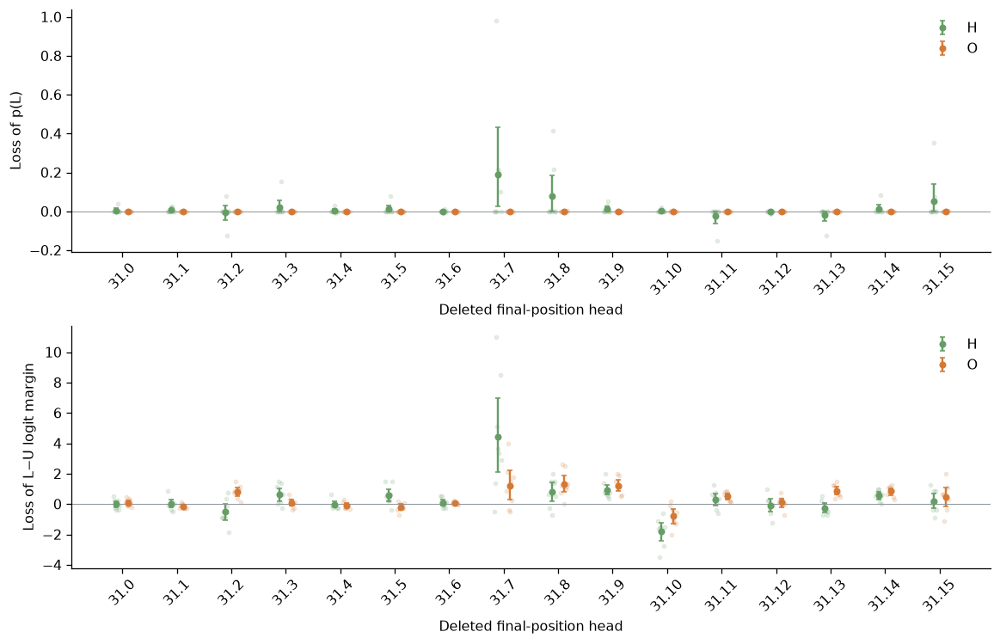

**Observation.** 31.7 has the largest mean p(L) loss in H: **0.18741 [0.02514, 0.43268]**, versus -0.00002 [-0.00005, 0.00000] in O. H's L predictions change from 5 to 4/8. The effect is uneven, with one problem contributing much of the mean. This nominates a conditional contributor, not a necessary or exclusive retrieval component; H and O differ in both native messages and receiving states.

In [20]:
plot_head_screen(
    opening_ablation_effects,
    opening_screen_summary,
    retrieval_block,
    ("H", "O"),
    margin_label="Loss of L−U logit margin",
)
selected_effects = {
    context: [
        effect
        for effect in opening_ablation_effects
        if effect["context"] == context and effect["head"] == retrieval_head
    ]
    for context in ("H", "O")
}
head_label = f"{retrieval_block}.{retrieval_head}"
hybrid_summary = opening_screen_summary["H"][retrieval_head]["loss_pL"]
ordinary_summary = opening_screen_summary["O"][retrieval_head]["loss_pL"]
hybrid_correct_before = sum(
    effect["before_correct"] for effect in selected_effects["H"]
)
hybrid_correct_after = sum(effect["after_correct"] for effect in selected_effects["H"])
display(
    Markdown(
        (
            f"**Observation.** {head_label} has the largest mean p(L) loss in H: **"
            f"{format_interval(hybrid_summary)}**, versus "
            f"{format_interval(ordinary_summary)} in O. H's L predictions change "
            f"from {hybrid_correct_before} to {hybrid_correct_after}/"
            f"{len(opening_problems)}. The effect is uneven, with one problem "
            "contributing much of the mean. This nominates a conditional "
            "contributor, not a necessary or exclusive retrieval component; H and "
            "O differ in both native messages and receiving states."
        )
    )
)


## 3. Try the same screen one block later

Deleting 31.7 weakened L in H, yet many answers survived and ordinary O remained
correct. One final-position message contributes without accounting for the whole
response. We can therefore ask whether a message in the immediately following
block also matters. Sequential blocks share the residual stream; this makes
block 32 a nearby place to inspect, without assuming direct communication.

Repeat the same single-head deletions in **H and ordinary O**, keeping the donor
residual transplant at block 31 for H. This is a first attempt to nominate another
head, using exactly the same p(L)-loss criterion.

From here onward use the 32 main families with single-token objects. That aligns
O and D's declaration-label positions for a later attention/value test. Every
block-32 comparison below uses this same cohort, so changing the intervention
will not also change the problems. These families are known exploratory data.

For recording, L is O's answer, D is the donor's answer, and C is D's label at
O's requested row. These are input-defined readouts; the first screen only uses L.


In [21]:
native_runs = {}


def native_main_runs(problem):
    """Cache only unmodified O/D activations, shared by every content test."""
    problem_id = problem["family_id"]
    if problem_id not in native_runs:
        ordinary, donor = problem["O"], problem["D"]
        assert ordinary["query_object"] == donor["query_object"]
        assert len(input_ids(ordinary)) == len(input_ids(donor))
        assert [span["box_token_position"] for span in ordinary["clause_spans"]] == [
            span["box_token_position"] for span in donor["clause_spans"]
        ]
        assert len(set(answer_roles(problem, "main").values())) == 3
        native_runs[problem_id] = {
            key: run_case(problem, key, f"native.{key}") for key in ("O", "D")
        }
    return native_runs[problem_id]


In [22]:
example_ordinary = example_problem["O"]
example_runs = native_main_runs(example_problem)
example_donor = example_problem["D"]
example_query_row = example_ordinary["query_row1based"] - 1
example_donor_row = example_donor["query_row1based"] - 1
print("Both prompts ask about:", example_ordinary["query_object"])
show_table(
    [
        {
            "row (counting from 1)": row + 1,
            "O declaration": " → ".join(example_ordinary["bindings"][row]),
            "D declaration": " → ".join(example_donor["bindings"][row]),
        }
        for row in (example_query_row, example_donor_row)
    ]
)
print("Ordinary O's correct label L:", example_ordinary["answer_letter"])


Both prompts ask about: brick


row (counting from 1),O declaration,D declaration
4,brick → Y,disk → P
6,television → Q,brick → I


Ordinary O's correct label L: Y


In [23]:
main_ablation_effects = []
for problem in main_problems:
    sources = native_main_runs(problem)
    donor_vector = sources["D"]["activations"][retrieval_block]["residual_before"][
        :, -1
    ]
    background = [residual_patch(retrieval_block, donor_vector)]
    hybrid = run_case(problem, "R", "screen.H", background)
    assert torch.equal(
        hybrid["activations"][retrieval_block]["residual_used"][:, -1], donor_vector
    )
    main_ablation_effects.extend(
        screen_heads(problem, "R", next_block, "H", hybrid, background)
    )
    main_ablation_effects.extend(
        screen_heads(problem, "O", next_block, "O", sources["O"])
    )
    del hybrid
main_screen_summary = {
    context: summarize_screen(main_ablation_effects, context) for context in ("H", "O")
}


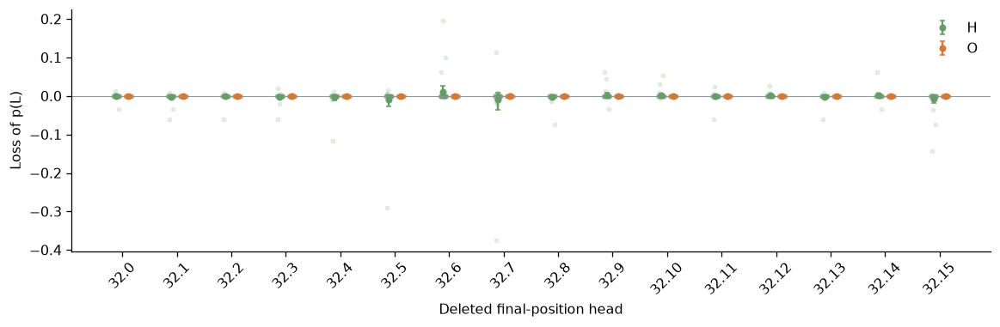

context,largest mean p(L) loss,loss (95% family interval)
H,32.6,"0.01110 [-0.00008, 0.02647]"
O,32.7,"0.00021 [0.00003, 0.00049]"


**Observation.** Mean probability effects are small, and all 32 ordinary answers survive every single-head deletion. H also gives no compelling second candidate. This does not show the heads do nothing: confidence, other label comparisons and earlier positions can still change. We return to the positively nominated 31.7 and ask what its message can carry.

In [24]:
plot_head_screen(main_ablation_effects, main_screen_summary, next_block, ("H", "O"))
show_table(
    [
        {
            "context": context,
            "largest mean p(L) loss": f"{next_block}.{rank_heads(main_screen_summary[context])[0]}",
            "loss (95% family interval)": format_interval(
                main_screen_summary[context][
                    rank_heads(main_screen_summary[context])[0]
                ]["loss_pL"]
            ),
        }
        for context in ("H", "O")
    ]
)
ordinary_answers_survive = all(
    predicts_role(observation(problem, f"screen.O.head{head}.zero"), "L")
    for problem in main_problems
    for head in range(N_HEADS)
)
assert ordinary_answers_survive
display(
    Markdown(
        (
            "**Observation.** Mean probability effects are small, and all "
            f"{len(main_problems)} ordinary answers survive every single-head "
            "deletion. H also gives no compelling second candidate. This does not "
            "show the heads do nothing: confidence, other label comparisons and "
            "earlier positions can still change. We return to the positively "
            f"nominated {retrieval_block}.{retrieval_head} and ask what its message "
            "can carry."
        )
    )
)


## 4. What label content can 31.7 supply?

The next-block deletions alone gave little guidance. For 31.7 we already have a
positive causal effect, so inspect its routing and test the content selected by
that routing. The receiver is now **ordinary O**, with no residual transplant.

O and D ask about the same object, at different rows and with different labels.
Call O's correct label **L**. We will also track **C**, D's label at O's requested
row, and **D's answer**, the label at the object's actual row in D. These three
letters differ. C is defined from the tables, before running an intervention.


First compare all 16 block-31 heads in ordinary O using the named selector
below. Its labels **31.0–31.15** are the actual model head indices; click a thumbnail
to lock that head, then select **31.7** to compare it with the others.

The two focused 31.7 views that follow show O and D. Click their **last Box
token** to see attention to preceding tokens. Rows are destinations and columns
are sources, as in TransformerLens. The single-head token widget calls its only
entry “Head 0”; that is model head 31.7. All views use the full token sequence and
unrenormalized attention weights.

The static bars below summarize 31.7's attention at declaration-label tokens,
retaining all remaining mass as “Other”. A large bar suggests a location to test;
it does not by itself show which content the head transmits or how the model uses it.

The CircuitsVis JavaScript is embedded in the output. Static plots remain readable
in viewers that disable scripts. The display dependency is circuitsvis==1.43.3.


In [25]:
# CircuitsVis uses the same [head, destination, source] layout as
# TransformerLens cache["pattern", layer][0]. No model/backend change is needed.
import circuitsvis as cv
from IPython.display import HTML, display


def show_attention(tokens, attention, head_names=None, token_hover=False):
    """Embed an ARENA-style view, including its JavaScript, in this output."""
    pattern = attention.detach().float().cpu()
    assert pattern.ndim == 3
    assert pattern.shape[1:] == (len(tokens), len(tokens))
    if head_names is not None:
        assert len(head_names) == pattern.shape[0]
    if token_hover:
        view = cv.attention.attention_patterns(tokens=tokens, attention=pattern)
    else:
        view = cv.attention.attention_heads(
            tokens=tokens,
            attention=pattern,
            attention_head_names=head_names,
            mask_upper_tri=True,
        )
    # The default repr may load from a CDN. local_src bundles the installed JS.
    display(HTML(view.local_src))


**Block 31 in O — all 16 heads. Select 31.7 to compare it with the others.**

**31.7 in O; correct label Y.**

**31.7 in D; correct label I.**

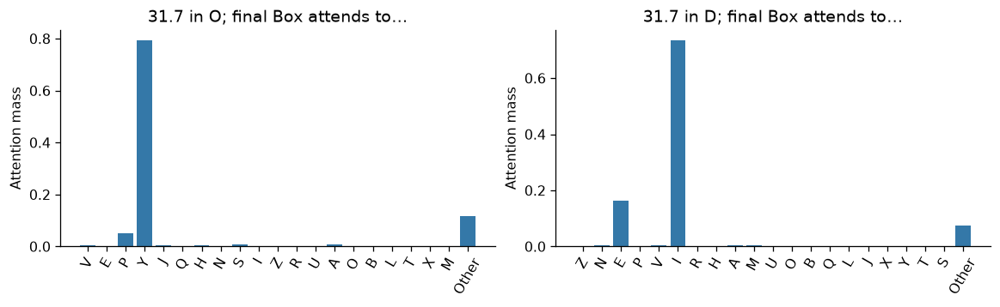

In [26]:
display(
    Markdown(
        "**Block 31 in O — all 16 heads. Select 31.7 to compare it with the others.**"
    )
)
show_attention(
    [tokenizer.decode([i]) for i in input_ids(example_ordinary)],
    example_runs["O"]["activations"][31]["attention"][0],
    [f"31.{h}" for h in range(16)],
)

for key, prompt in [("O", example_ordinary), ("D", example_donor)]:
    display(Markdown(f"**31.7 in {key}; correct label {prompt['answer_letter']}.**"))
    show_attention(
        [tokenizer.decode([i]) for i in input_ids(prompt)],
        example_runs[key]["activations"][31]["attention"][0, [7]],
        ["31.7"],
        token_hover=True,
    )
fig, axes = plt.subplots(1, 2, figsize=(10, 3), layout="constrained")
for ax, key, prompt in zip(axes, ["O", "D"], [example_ordinary, example_donor]):
    pos = [c["box_token_position"] for c in prompt["clause_spans"]]
    a = (
        example_runs[key]["activations"][31]["attention"][0, 7, -1]
        .float()
        .cpu()
        .numpy()
    )
    ax.bar(range(21), list(a[pos]) + [float(a.sum() - a[pos].sum())], color=BLUE)
    ax.set_xticks(
        range(21), [label for _, label in prompt["bindings"]] + ["Other"], rotation=60
    )
    ax.set_title(f"31.7 in {key}; final Box attends to…")
    ax.set_ylabel("Attention mass")
plt.show()


For a head, `Z = A @ V`: attention weights select and mix value vectors. Keep
31.7's attention from O, but supply values from D. If the label position receiving
most attention carries useful content, the recombined message should favor C,
the label printed at that same position in D—not necessarily D's own answer.

We construct this message offline, then patch **only the 128-dimensional Z slice
for head 7 at the final `Box`, immediately before `o_proj`**. We do not edit live
queries, keys, or shared values. All other messages and later computation run normally.
In TransformerLens terms this is a `hook_z` edit, before multiplication by `W_O`;
the saved attention tensor has the same layout as `cache["pattern", layer]`.

The helper preserves the full matrix shape for `A @ V` because changing it can
change BF16 rounding. Shared KV heads are repeated to match the 16 query heads;
only the selected result is inserted. `positions` lets us test donor values at
just the selected label token while retaining O's other values.

First reconstruct O-attention/O-values. It must reproduce both the original Z
slice and final logits exactly before we interpret the O-attention/D-values edit.


In [27]:
def repeat_kv(values, query_heads):
    """[batch, KV head, sequence, width] → one value bank per query head."""
    groups = query_heads // values.shape[1]
    return (
        values[:, :, None]
        .expand(-1, -1, groups, -1, -1)
        .reshape(values.shape[0], query_heads, values.shape[2], values.shape[3])
    )


def compose_head_message(ordinary_cache, value_cache, head, label_positions=None):
    """Keep ordinary attention and change the selected shared value bank."""
    attention = ordinary_cache["attention"]
    values = ordinary_cache["values"].clone()
    value_group = head // (attention.shape[1] // values.shape[2])
    if label_positions is None:
        values[:, :, value_group] = value_cache["values"][:, :, value_group]
    else:
        values[:, label_positions, value_group] = value_cache["values"][
            :, label_positions, value_group
        ]
    repeated_values = repeat_kv(values.transpose(1, 2), attention.shape[1])
    # Preserve the full matrix product: final-row-only matmul changes BF16 rounding.
    head_outputs = (attention @ repeated_values).transpose(1, 2).contiguous()
    return head_outputs[:, -1, head]


crossed_messages, challenged_runs = {}, {}


def ensure_content_test(problem, block, head, pairing, *, retain_challenge=False):
    """Run each identity/full/label-only crossing once and reuse its observation."""
    assert pairing in ("OO", "OD", "OD.label")
    condition = f"AV.{block}.{pairing}"
    if has_case(problem, condition):
        return observation(problem, condition)
    sources = native_main_runs(problem)
    ordinary_cache = sources["O"]["activations"][block]
    value_cache = sources["O" if pairing == "OO" else "D"]["activations"][block]
    label_positions = None
    if pairing == "OD.label":
        prompt = problem["O"]
        label_positions = prompt["clause_spans"][prompt["query_row1based"] - 1][
            "box_token_positions"
        ]
    message = compose_head_message(ordinary_cache, value_cache, head, label_positions)
    if pairing == "OO":
        assert torch.equal(message, ordinary_cache["head_output_before"][:, -1, head])
    result = run_case(
        problem, "O", condition, [head_output_patch(block, head, message)]
    )
    assert torch.equal(result["logits"][:, 0], sources["O"]["logits"][:, 0])
    if pairing == "OO":
        assert torch.equal(result["logits"], sources["O"]["logits"])
        checks[f"content_identity:{problem['family_id']}:{block}"] = True
    if pairing == "OD":
        crossed_messages[problem["family_id"], block] = message
    if retain_challenge:
        assert pairing == "OD" and block == retrieval_block
        challenged_runs[problem["family_id"]] = result
    return result["observation"]


In [28]:
ensure_content_test(example_problem, retrieval_block, retrieval_head, "OO")
ensure_content_test(
    example_problem, retrieval_block, retrieval_head, "OD", retain_challenge=True
)
first_crossing = f"AV.{retrieval_block}.OD"
show_table(
    [
        {
            "condition": condition,
            "p(correct L)": probability_of_role(
                observation(example_problem, condition), "L"
            ),
            "p(predicted C)": probability_of_role(
                observation(example_problem, condition), "C"
            ),
            "C−L logit margin": logit_margin(
                observation(example_problem, condition), "C", "L"
            ),
            "top token": top_label(observation(example_problem, condition)),
        }
        for condition in ("native.O", first_crossing)
    ]
)
display(
    Markdown(
        (
            "The crossed label gains evidence, but the ordinary answer still wins "
            "in this example. Other computation can outweigh the supplied message. "
            "Check whether this also happens across the cohort."
        )
    )
)


condition,p(correct L),p(predicted C),C−L logit margin,top token
native.O,0.9999961853100103,2.061145759776467e-09,-20.0,Y
AV.31.OD,0.9924147783575292,0.007577180336948762,-4.875,Y


The crossed label gains evidence, but the ordinary answer still wins in this example. Other computation can outweigh the supplied message. Check whether this also happens across the cohort.

In [29]:
for problem in main_problems:
    ensure_content_test(problem, retrieval_block, retrieval_head, "OO")
    ensure_content_test(
        problem, retrieval_block, retrieval_head, "OD", retain_challenge=True
    )

crossing_survivors = sum(
    predicts_role(observation(problem, first_crossing), "L")
    for problem in main_problems
)
show_table(
    [
        {
            "condition": condition,
            "mean p(L)": condition_values(
                main_problems, condition, probability_L
            ).mean(),
            "mean p(C)": condition_values(
                main_problems, condition, probability_C
            ).mean(),
            "unique L predictions": sum(
                predicts_role(observation(problem, condition), "L")
                for problem in main_problems
            ),
        }
        for condition in ("native.O", first_crossing)
    ]
)
display(
    Markdown(
        (
            f"**Observation.** The crossed message leaves **{crossing_survivors}/"
            f"{len(main_problems)}** answers correct. We now have a specific "
            "challenge: misleading evidence from the first head. Which next-block "
            "messages help L survive it?"
        )
    )
)


condition,mean p(L),mean p(C),unique L predictions
native.O,0.9996904354764669,1.6679038180969706e-08,32
AV.31.OD,0.8006997663082501,0.19908373554178369,27


**Observation.** The crossed message leaves **27/32** answers correct. We now have a specific challenge: misleading evidence from the first head. Which next-block messages help L survive it?

## 5. Which later messages help the correct answer survive?

Repeat the **same 16 block-32 deletions**, this time in ordinary O with 31.7's
crossed message fixed. Call this context **X**. There is no residual transplant;
only the final-position Z31.7 slice is replaced before the deletion at block 32.
The supplied vector comes from unmodified O/D and stays identical across runs.

Rank by the same signed mean **p(L) loss**. Keep H and ordinary O visible on the
same problems. Also inspect loss of the **L−C logit margin**, since C is now the
explicit competing answer and ordinary probabilities can hide effects near one.
This asks about conditional answer support, not whether a head detects mistakes.
All intervals resample families; these screening intervals are exploratory and
unadjusted for choosing among heads.


In [30]:
for problem in main_problems:
    # These are the same live runs displayed above, not a second model invocation.
    baseline = challenged_runs.pop(problem["family_id"])
    message = crossed_messages[problem["family_id"], retrieval_block]
    background = [head_output_patch(retrieval_block, retrieval_head, message)]
    first_cache = baseline["activations"][retrieval_block]
    assert torch.equal(first_cache["head_output_used"][:, -1, retrieval_head], message)
    assert torch.equal(first_cache["residual_before"], first_cache["residual_used"])
    main_ablation_effects.extend(
        screen_heads(problem, "O", next_block, "X", baseline, background)
    )
    del baseline
main_screen_summary["X"] = summarize_screen(main_ablation_effects, "X")
support_head = rank_heads(main_screen_summary["X"])[0]
head_sites = {retrieval_block: retrieval_head, next_block: support_head}


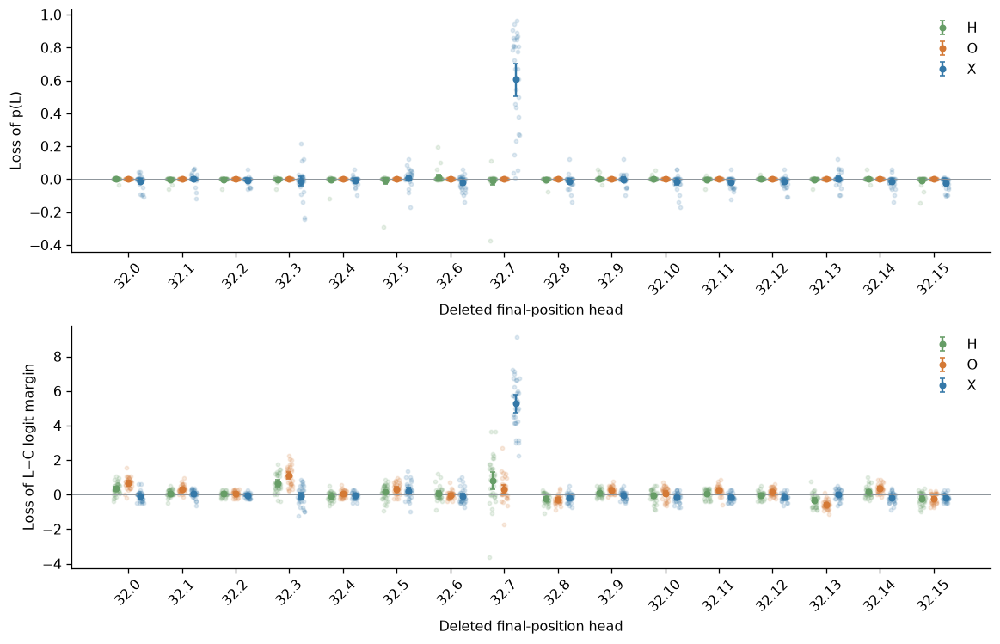

X rank,head,p(L) loss (95% interval)
1,32.7,"0.60715 [0.50600, 0.70182]"
2,32.5,"0.00841 [-0.00994, 0.02489]"
3,32.13,"0.00256 [-0.01141, 0.01660]"
4,32.1,"0.00204 [-0.01054, 0.01338]"
5,32.9,"-0.00056 [-0.01186, 0.01179]"
6,32.2,"-0.00616 [-0.01407, 0.00149]"
7,32.4,"-0.00695 [-0.01598, 0.00143]"
8,32.8,"-0.01194 [-0.02553, 0.00168]"
9,32.0,"-0.01228 [-0.02557, -0.00049]"
10,32.3,"-0.01267 [-0.04170, 0.01577]"


**Observation.** X nominates **32.7**, with the unique largest loss in **32/32** problems. Its gap over 32.5 is **0.59875 [0.49415, 0.69676]**. This identifies a contribution under a defined challenge; naturally computed head content and receiving states can both change between contexts, so it does not establish active compensation.

In [31]:
plot_head_screen(
    main_ablation_effects,
    main_screen_summary,
    next_block,
    ("H", "O", "X"),
    margin_label="Loss of L−C logit margin",
)
head_ranking = rank_heads(main_screen_summary["X"])
runner_up = head_ranking[1]
selection_gap = bootstrap_mean(
    screen_values(main_ablation_effects, "X", support_head)
    - screen_values(main_ablation_effects, "X", runner_up),
    SCREEN_SEED,
    10000,
)
problem_by_head = np.stack(
    [screen_values(main_ablation_effects, "X", head) for head in range(N_HEADS)], axis=1
)
unique_wins = sum(
    np.flatnonzero(effects == effects.max()).tolist() == [support_head]
    for effects in problem_by_head
)
show_table(
    [
        {
            "X rank": rank + 1,
            "head": f"{next_block}.{head}",
            "p(L) loss (95% interval)": format_interval(
                main_screen_summary["X"][head]["loss_pL"]
            ),
        }
        for rank, head in enumerate(head_ranking)
    ]
)
display(
    Markdown(
        (
            f"**Observation.** X nominates **{next_block}.{support_head}**, with "
            f"the unique largest loss in **{unique_wins}/{len(main_problems)}** "
            f"problems. Its gap over {next_block}.{runner_up} is **"
            f"{format_interval(selection_gap)}**. This identifies a contribution "
            "under a defined challenge; naturally computed head content and "
            "receiving states can both change between contexts, so it does not "
            "establish active compensation."
        )
    )
)


### Inspect the causally nominated head

The deletion screen supplies the candidate. We now inspect its ordinary-O
attention alongside 31.7, asking whether its routing suggests a content test.
The highlighted column below is O's correct label; attention magnitude does not
enter the selection rule. The viewer shows all 16 actual block-32 head labels.
A similar-looking attention pattern would not establish the same algorithm.


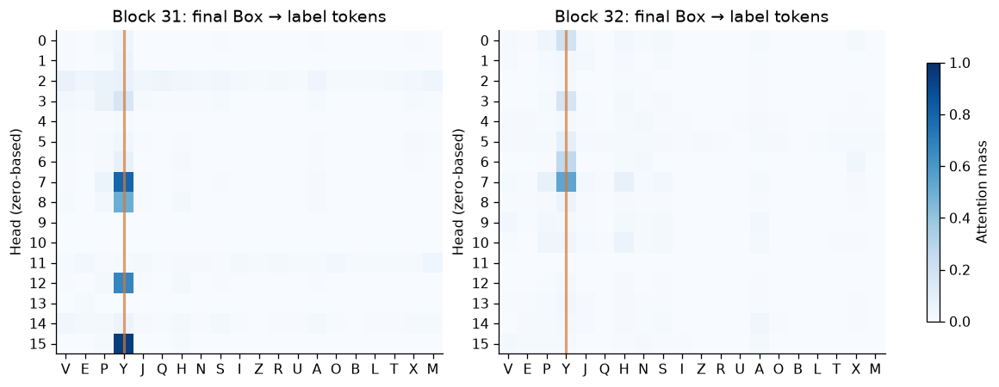

Candidate from the X deletion screen: 32.7


In [32]:
example_label_positions = [
    c["box_token_position"] for c in example_ordinary["clause_spans"]
]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), layout="constrained")
for ax, layer in zip(axes, (31, 32)):
    a = (
        example_runs["O"]["activations"][layer]["attention"][0, :, -1]
        .float()
        .cpu()
        .numpy()
    )
    image = ax.imshow(
        a[:, example_label_positions], vmin=0, vmax=1, aspect="auto", cmap="Blues"
    )
    ax.axvline(example_query_row, color=ORANGE, linewidth=2, alpha=0.7)
    ax.set_xticks(range(20), [label for _, label in example_ordinary["bindings"]])
    ax.set_yticks(range(16))
    ax.set_ylabel("Head (zero-based)")
    ax.set_title(f"Block {layer}: final Box → label tokens")
fig.colorbar(image, ax=axes, label="Attention mass", shrink=0.8)
plt.show()
print("Candidate from the X deletion screen:", f"32.{support_head}")
show_attention(
    [tokenizer.decode([i]) for i in input_ids(example_ordinary)],
    example_runs["O"]["activations"][32]["attention"][0],
    [f"32.{h}" for h in range(16)],
)


Now apply the same O-attention/D-values crossing to the **two causally nominated heads**, each at its own layer,
across the 32 previously studied families. O remains the receiver throughout.
Reuse the first head’s O-attention/O-values check and run it for the second: this identity control must reproduce
both the original Z slice and the final logits exactly.

One content control uses donor values only at O's selected label token. If that
retains much of the effect, it supports that token as an important content source;
it does not establish exclusive copying from one token.

Measure both the probability of C and the **C−L logit margin**. The latter is
`logit(C) − logit(L)`, equivalently the log probability ratio. It reveals evidence
shifts even while the model remains extremely confident in L. Intervals below
resample problem families, not repeated tokens or forwards.


In [33]:
for problem in main_problems:
    for block, head in head_sites.items():
        for pairing in ("OO", "OD", "OD.label"):
            ensure_content_test(problem, block, head, pairing)

content_effects = {}
for block in head_sites:
    identity, crossed, label_only = [
        f"AV.{block}.{pairing}" for pairing in ("OO", "OD", "OD.label")
    ]
    content_effects[block] = {
        "probability": paired_summary(main_problems, crossed, identity, probability_C),
        "margin": paired_summary(main_problems, crossed, identity, margin_C_minus_L),
        "label_minus_full": paired_summary(
            main_problems, label_only, crossed, probability_C
        ),
        "label_margin": paired_summary(
            main_problems, label_only, identity, margin_C_minus_L
        ),
    }


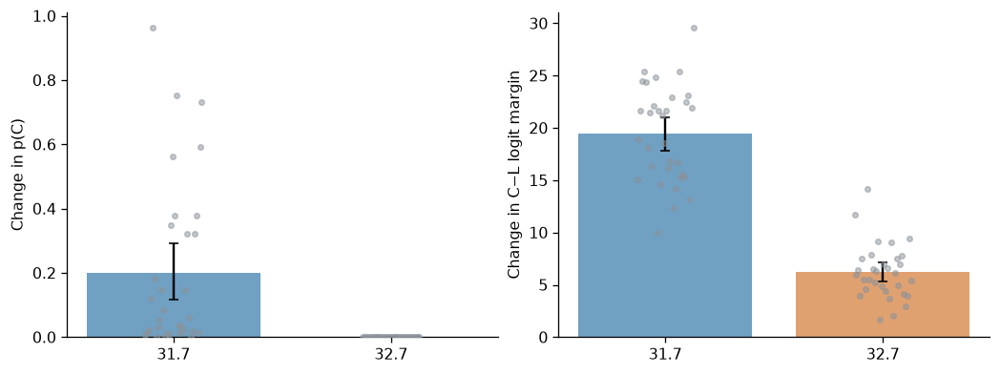

head,C−L margin shift (95% CI),Label-only C−L margin shift (95% CI)
31.7,"19.41602 [17.85547, 21.01763]","19.63867 [18.11714, 21.18955]"
32.7,"6.21680 [5.36523, 7.12700]","6.66211 [5.75977, 7.60161]"


**Observation.** Both crossings move relative evidence toward the input-predicted label, with unequal effects. The label-only control retains much of the shift. This supports selected label content in both messages without establishing identical lookup algorithms. What happens when both crossed messages are supplied together?

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.3), layout="constrained")
for axis, metric, summary_key, label in zip(
    axes,
    (probability_C, margin_C_minus_L),
    ("probability", "margin"),
    ("Change in p(C)", "Change in C−L logit margin"),
):
    estimates = []
    for index, block in enumerate(head_sites):
        differences = condition_values(
            main_problems, f"AV.{block}.OD", metric
        ) - condition_values(main_problems, f"AV.{block}.OO", metric)
        axis.scatter(
            index + np.linspace(-0.13, 0.13, len(differences)),
            differences,
            s=12,
            color=GREY,
            alpha=0.5,
            zorder=3,
        )
        estimates.append(content_effects[block][summary_key])
    plot_bars(axis, range(2), estimates, color=[BLUE, ORANGE], alpha=0.7)
    axis.set_xticks(range(2), [f"{block}.{head}" for block, head in head_sites.items()])
    axis.set_ylabel(label)
    axis.axhline(0, color=GREY, linewidth=0.6)
plt.show()
show_table(
    [
        {
            "head": f"{block}.{head}",
            "C−L margin shift (95% CI)": format_interval(
                content_effects[block]["margin"]
            ),
            "Label-only C−L margin shift (95% CI)": format_interval(
                content_effects[block]["label_margin"]
            ),
        }
        for block, head in head_sites.items()
    ]
)
display(
    Markdown(
        (
            "**Observation.** Both crossings move relative evidence toward the "
            "input-predicted label, with unequal effects. The label-only control "
            "retains much of the shift. This supports selected label content in "
            "both messages without establishing identical lookup algorithms. What "
            "happens when both crossed messages are supplied together?"
        )
    )
)


## 6. What happens when both messages are crossed?

Either individual crossing can leave the correct answer intact. The most direct
next test is to supply **both crossed messages in the same ordinary O run**.
Both predict the same wrong label C. In the worked example, that is P rather than
the correct Y. Can the model withstand the joint perturbation too?

Construct each message from its own layer's **unmodified O/D tensors**, exactly
as above, then insert both final-Box Z slices before their respective output
projections. In particular, block 32's supplied vector is not reconstructed from
an already perturbed run. All other computation proceeds normally.


In [35]:
# Reuse the vectors built from unmodified O/D in the content tests.
for problem in main_problems:
    patches = [
        head_output_patch(block, head, crossed_messages[problem["family_id"], block])
        for block, head in head_sites.items()
    ]
    result = run_case(problem, "O", "followup.both.OD", patches)
    assert torch.equal(
        result["logits"][:, 0], native_main_runs(problem)["O"]["logits"][:, 0]
    )
    del result
joint_conditions = (first_crossing, f"AV.{next_block}.OD", "followup.both.OD")
joint_summaries = [
    bootstrap_mean(
        condition_values(main_problems, condition, probability_C), CONTENT_SEED
    )
    for condition in joint_conditions
]


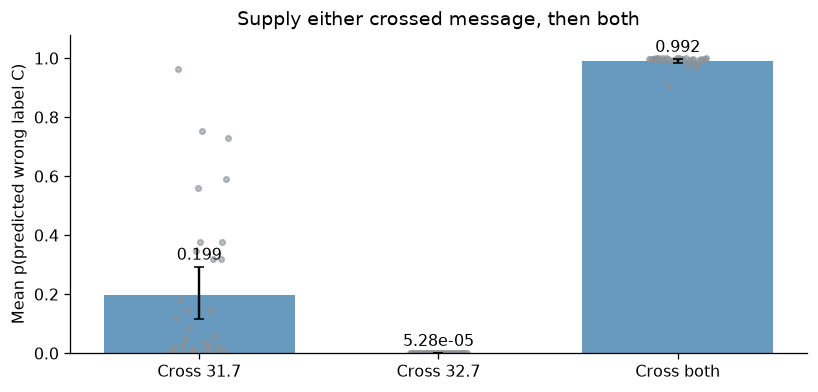

worked example,p(correct L),p(predicted C),top token
Ordinary O,0.9999961853100103,2.061145759776467e-09,Y
Cross 31.7,0.9924147783575292,0.007577180336948762,Y
Cross 32.7,0.9997330068404254,0.00026118880305398765,Y
Cross both,0.001169504730850184,0.9988257631983881,P


**Observation.** Joint crossing gives mean p(C) **0.992**, with C winning **32/32** problems. The worked answer changes from Y to P. This is consistent with overlapping answer support, without establishing active compensation or direct communication.

In [36]:
fig, axis = plt.subplots(figsize=(7, 3.3), layout="constrained")
plot_bars(axis, range(3), joint_summaries, color=[BLUE, ORANGE, BLUE], alpha=0.75)
for index, condition in enumerate(joint_conditions):
    points = condition_values(main_problems, condition, probability_C)
    axis.scatter(
        index + np.linspace(-0.12, 0.12, len(points)),
        points,
        color=GREY,
        s=12,
        alpha=0.6,
    )
    axis.text(
        index,
        joint_summaries[index]["ci95"][1] + 0.025,
        f"{joint_summaries[index]['mean']:.3g}",
        ha="center",
    )
axis.set_xticks(
    range(3),
    [
        f"Cross {retrieval_block}.{retrieval_head}",
        f"Cross {next_block}.{support_head}",
        "Cross both",
    ],
)
axis.set(
    ylabel="Mean p(predicted wrong label C)",
    ylim=(0, 1.08),
    title="Supply either crossed message, then both",
)
plt.show()
show_table(
    [
        {
            "worked example": name,
            "p(correct L)": probability_of_role(
                observation(example_problem, condition), "L"
            ),
            "p(predicted C)": probability_of_role(
                observation(example_problem, condition), "C"
            ),
            "top token": top_label(observation(example_problem, condition)),
        }
        for name, condition in [
            ("Ordinary O", "native.O"),
            (f"Cross {retrieval_block}.{retrieval_head}", first_crossing),
            (f"Cross {next_block}.{support_head}", f"AV.{next_block}.OD"),
            ("Cross both", "followup.both.OD"),
        ]
    ]
)
joint_wins = sum(
    predicts_role(observation(problem, "followup.both.OD"), "C")
    for problem in main_problems
)
example_roles = answer_roles(example_problem, "main")
display(
    Markdown(
        (
            "**Observation.** Joint crossing gives mean p(C) **"
            f"{joint_summaries[2]['mean']:.3f}**, with C winning **{joint_wins}/"
            f"{len(main_problems)}** problems. The worked answer changes from "
            f"{example_roles['L']} to {example_roles['C']}. This is consistent with "
            "overlapping answer support, without establishing active compensation "
            "or direct communication."
        )
    )
)


### Separate removing support from supplying competing evidence

The challenged screen already deleted the second head. Joint crossing also
supplies its crossed message, so the joint effect could involve **removing
ordinary support**, **adding different label evidence**, or both.

Compare that already-measured zero with the crossed message, then apply the
same treatments symmetrically to both heads. This completes a **3×3 grid**:
recompute normally, zero, or cross. Reuse all conditions measured above;
only the remaining combinations need running.

“Recompute normally” at block 32 allows it to respond to the altered state from
block 31. Crossed vectors always come from unmodified O/D. Only the named
final-position Z slices are replaced. This comparison can distinguish effects
of the two interventions without identifying a special error-response mechanism.


In [37]:
# Reuse the vectors built from unmodified O/D in the content tests.
treatments = ("normal", "zero", "cross")
grid_conditions = {
    ("normal", "normal"): "native.O",
    ("normal", "zero"): f"screen.O.head{support_head}.zero",
    ("normal", "cross"): f"AV.{next_block}.OD",
    ("zero", "normal"): "zero.31",
    ("zero", "zero"): "zero.31.32",
    ("zero", "cross"): "followup.reverse32.zero31",
    ("cross", "normal"): first_crossing,
    ("cross", "zero"): f"screen.X.head{support_head}.zero",
    ("cross", "cross"): "followup.both.OD",
}
for problem in main_problems:
    for treatment_pair, condition in grid_conditions.items():
        if has_case(problem, condition):
            continue  # Previously measured conditions occupy the same grid cells.
        patches = []
        for (block, head), treatment in zip(head_sites.items(), treatment_pair):
            if treatment == "normal":
                continue
            message = crossed_messages[problem["family_id"], block]
            value = torch.zeros_like(message) if treatment == "zero" else message
            patches.append(head_output_patch(block, head, value))
        result = run_case(problem, "O", condition, patches)
        assert torch.equal(
            result["logits"][:, 0], native_main_runs(problem)["O"]["logits"][:, 0]
        )
        del result

grid_summary = {}
for treatment_pair, condition in grid_conditions.items():
    grid_summary[treatment_pair] = {
        "condition": condition,
        "pC": bootstrap_mean(
            condition_values(main_problems, condition, probability_C), CONTENT_SEED
        ),
        "margin": bootstrap_mean(
            condition_values(main_problems, condition, margin_C_minus_L), CONTENT_SEED
        ),
    }
both_minus_zero = paired_summary(
    main_problems, "followup.both.OD", grid_conditions["cross", "zero"], probability_C
)
both_minus_zero_margin = paired_summary(
    main_problems,
    "followup.both.OD",
    grid_conditions["cross", "zero"],
    margin_C_minus_L,
)


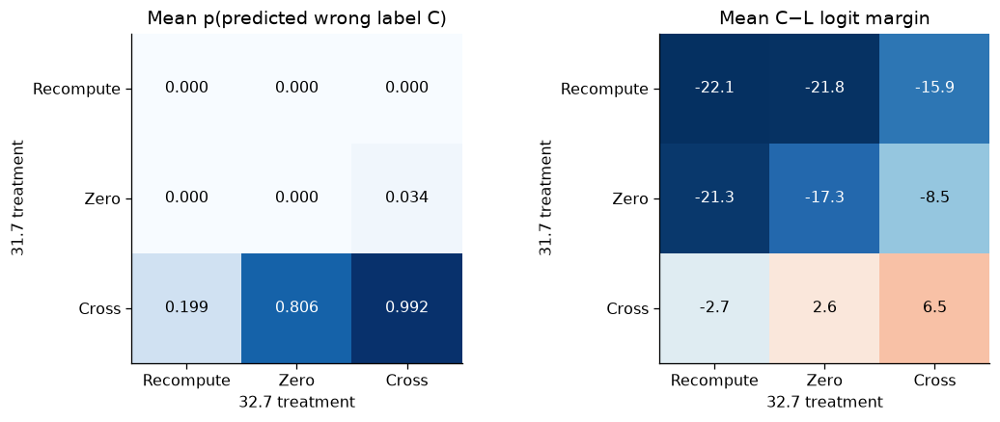

**Deletion controls.** Both final-position messages can be zeroed while **32/32** ordinary answers remain correct. Under the first crossing, deleting the second message raises mean p(C) from **0.199** to **0.806**. Joint crossing gives **0.992**. Its paired increase over zeroing the second message is 0.18641 [0.09941, 0.28687] in p(C), or 3.88672 [3.36709, 4.40635] logits. The reverse direction is weaker. These are conditional contributions, not evidence of an explicit vote or head-to-head communication.

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.7), layout="constrained")
for axis, metric, title, number_format in zip(
    axes,
    ("pC", "margin"),
    ("Mean p(predicted wrong label C)", "Mean C−L logit margin"),
    (".3f", ".1f"),
):
    matrix = np.array(
        [
            [grid_summary[first, second][metric]["mean"] for second in treatments]
            for first in treatments
        ]
    )
    limit = max(abs(matrix.min()), abs(matrix.max()))
    scale = (
        {"vmin": 0, "vmax": 1, "cmap": "Blues"}
        if metric == "pC"
        else {"vmin": -limit, "vmax": limit, "cmap": "RdBu_r"}
    )
    axis.imshow(matrix, **scale)
    for row in range(3):
        for column in range(3):
            value = matrix[row, column]
            dark = value > 0.5 if metric == "pC" else abs(value) > 0.6 * limit
            axis.text(
                column,
                row,
                format(value, number_format),
                ha="center",
                va="center",
                color="white" if dark else "black",
            )
    axis.set_xticks(range(3), ["Recompute", "Zero", "Cross"])
    axis.set_yticks(range(3), ["Recompute", "Zero", "Cross"])
    axis.set_xlabel(f"{next_block}.{support_head} treatment")
    axis.set_ylabel(f"{retrieval_block}.{retrieval_head} treatment")
    axis.set_title(title)
plt.show()
ordinary_survivors = sum(
    predicts_role(observation(problem, "zero.31.32"), "L") for problem in main_problems
)
challenged_zero = grid_conditions["cross", "zero"]
mean_C_first_crossed = grid_summary["cross", "normal"]["pC"]["mean"]
mean_C_support_deleted = grid_summary["cross", "zero"]["pC"]["mean"]
display(
    Markdown(
        (
            "**Deletion controls.** Both final-position messages can be zeroed "
            f"while **{ordinary_survivors}/{len(main_problems)}** ordinary answers "
            "remain correct. Under the first crossing, deleting the second message "
            f"raises mean p(C) from **{mean_C_first_crossed:.3f}** to **"
            f"{mean_C_support_deleted:.3f}**. Joint crossing gives **"
            f"{joint_summaries[2]['mean']:.3f}**. Its paired increase over zeroing "
            f"the second message is {format_interval(both_minus_zero)} in p(C), or "
            f"{format_interval(both_minus_zero_margin)} logits. The reverse "
            "direction is weaker. These are conditional contributions, not "
            "evidence of an explicit vote or head-to-head communication."
        )
    )
)


## 7. What we learned

A block-32 final-message deletion can be weak in H/O yet large under a fixed misleading message.
That challenged screen nominates the second head. Attention/value crossing then
makes both candidate heads supply input-predicted label
evidence, with unequal effects. Crossing both can overturn the correct answer even
when either individual crossing is tolerated. Deletion controls show that a final
message can be dispensable for ordinary accuracy yet consequential under misleading
evidence from another head.

This is an exploratory account of selected content and conditional answer support,
not a complete circuit or evidence of direct communication between heads. Earlier
positions remain active. The source of the context dependence remains unresolved,
and these previously studied problem families provide no fresh held-out validation.


In [39]:
assert all(checks.values())
main_rows = [row for (study, _, _), row in observations.items() if study == "main"]
opening_rows = [
    row for (study, _, _), row in observations.items() if study == "opening"
]
assert len(main_rows) == 61 * len(main_problems)
assert len(opening_rows) == 72 * len(opening_problems)

# All summaries below were already computed for the displayed analyses.
summary = {
    "version": "readability-draft-v1",
    "main_records": len(main_rows),
    "opening_records": len(opening_rows),
    "retrieval_block": retrieval_block,
    "retrieval_head": retrieval_head,
    "support_head": support_head,
    "residual_scan": residual_summary,
    "opening_screen": opening_screen_summary,
    "main_screen": main_screen_summary,
    "selection_gap": selection_gap,
    "content_effects": content_effects,
    "joint": joint_summaries,
    "grid": {"/".join(pair): value for pair, value in grid_summary.items()},
    "both_minus_zero": both_minus_zero,
    "both_minus_zero_margin": both_minus_zero_margin,
}
(RUN_DIR / "inputs.json").write_text(json.dumps(main_problems))
(RUN_DIR / "summary.json").write_text(json.dumps(summary, indent=2))
(RUN_DIR / "checks.json").write_text(json.dumps(checks, indent=2))
torch.save(tensor_witnesses, RUN_DIR / "tensor-witnesses.pt")
print(
    f"Completed {len(main_problems)} main problems: "
    f"{len(main_rows)} main and {len(opening_rows)} opening observations."
)
print("Inputs, results, edit receipts and witnesses:", RUN_DIR)


Completed 32 main problems: 1952 main and 576 opening observations.
Inputs, results, edit receipts and witnesses: /workspace/reasoning-interp/runs/notebook-binding-20261113T000932Z-f8303614


### Running the notebook yourself

Download `binding-heads.ipynb` and use the pinned Python 3.12/CUDA environment
described in section 1. If you also download `requirements.txt`, the equivalent
installation command, after installing the CUDA-enabled Torch wheel, is:

```bash
python -m pip install -r requirements.txt
jupyter lab binding-heads.ipynb
```

Restart the kernel after installation, then choose **Restart Kernel and Run All
Cells**. Keep `RUN_ALL_FAMILIES=True` to reproduce the eight opening and 32 main
problems. Every input, intervention, statistic and plot is generated inside this
notebook; no previous experiment results are loaded. The model and tokenizer
are downloaded from their pinned public Hugging Face revision on the first run.
Each execution writes its inputs, results and checks to a fresh `runs/` directory
under the working directory.

The experiments use the A40 environment described in section 1.
Other GPUs or software versions have not been validated here and may produce
numerical differences. These are previously studied exploratory problems, not
fresh held-out validation.

Source inspiration: [Mixing Mechanisms](https://arxiv.org/html/2510.06182v2) and
the [authors' code](https://github.com/yoavgur/mixing-mechs/tree/c53372c606e7cadf2494d2ac7b08e466042052df).
The vocabulary and matched task derive from that release; intact chat, unfinished
`Box` and individual-head interventions are adaptations.
